In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
data = {
    'Hours_Studied': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
                      11, 12, 13, 14, 15],

    'Attendance': [60, 62, 65, 68, 70, 72, 75, 78, 80, 82,
                   85, 87, 90, 92, 95],

    'Assignments': [2, 2, 3, 3, 4, 4, 5, 5, 6, 6,
                     7, 7, 8, 9, 9],

    'Marks': [35, 40, 44, 49, 54, 59, 64, 69, 73, 78,
              82, 87, 90, 94, 97]
}

df = pd.DataFrame(data)

df

,Hours_Studied,Attendance,Assignments,Marks
0,1,60,2,35
1,2,62,2,40
2,3,65,3,44
3,4,68,3,49
4,5,70,4,54
5,6,72,4,59
6,7,75,5,64
7,8,78,5,69
8,9,80,6,73
9,10,82,6,78


In [3]:
X = df[['Hours_Studied', 'Attendance', 'Assignments']]
y = df['Marks']

print("Independent Variables:")
print(X.columns.tolist())

print("\nDependent Variable:")
print("Marks")

Independent Variables:
['Hours_Studied', 'Attendance', 'Assignments']

Dependent Variable:
Marks


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 12
Testing samples: 3


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features standardized successfully.")

Features standardized successfully.


In [6]:
linear_model = LinearRegression()

ridge_model = Ridge(alpha=1.0)

lasso_model = Lasso(alpha=0.1)

print("Models created successfully.")

Models created successfully.


In [7]:
linear_model.fit(X_train_scaled, y_train)

ridge_model.fit(X_train_scaled, y_train)

lasso_model.fit(X_train_scaled, y_train)

print("All models trained successfully.")

All models trained successfully.


In [8]:
linear_pred = linear_model.predict(X_test_scaled)

ridge_pred = ridge_model.predict(X_test_scaled)

lasso_pred = lasso_model.predict(X_test_scaled)

print("Predictions generated successfully.")

Predictions generated successfully.


In [9]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Ridge Regression',
        'Lasso Regression'
    ],

    'MSE': [
        mean_squared_error(y_test, linear_pred),
        mean_squared_error(y_test, ridge_pred),
        mean_squared_error(y_test, lasso_pred)
    ],

    'R2 Score': [
        r2_score(y_test, linear_pred),
        r2_score(y_test, ridge_pred),
        r2_score(y_test, lasso_pred)
    ]
})

results

,Model,MSE,R2 Score
0,Linear Regression,1.833333,0.996439
1,Ridge Regression,10.922399,0.978787
2,Lasso Regression,2.699582,0.994757


In [10]:
coefficients = pd.DataFrame({
    'Feature': X.columns,

    'Linear Regression': linear_model.coef_,

    'Ridge Regression': ridge_model.coef_,

    'Lasso Regression': lasso_model.coef_
})

coefficients

,Feature,Linear Regression,Ridge Regression,Lasso Regression
0,Hours_Studied,14.673471,6.358303,14.825121
1,Attendance,5.233439,6.417169,3.844676
2,Assignments,-1.144886,5.492560,0.000000


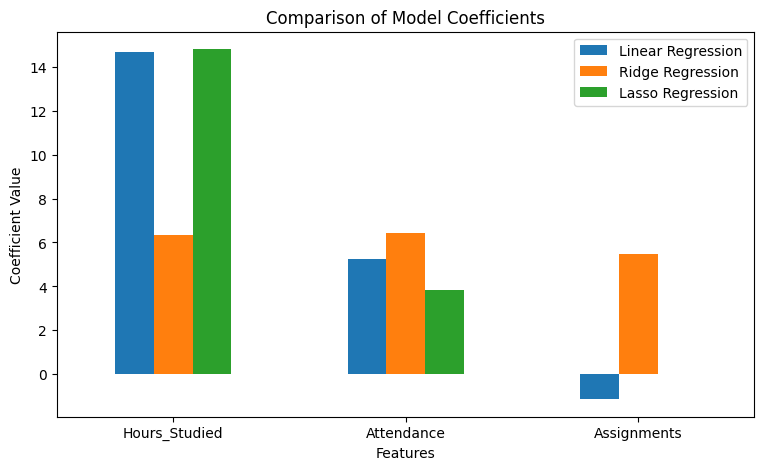

In [11]:
coefficients.set_index('Feature').plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Comparison of Model Coefficients')
plt.xlabel('Features')
plt.ylabel('Coefficient Value')
plt.xticks(rotation=0)

plt.show()

In [12]:
new_student = pd.DataFrame({
    'Hours_Studied': [10],
    'Attendance': [85],
    'Assignments': [7]
})

new_student_scaled = scaler.transform(new_student)

ridge_prediction = ridge_model.predict(new_student_scaled)

print("Predicted Marks using Ridge Regression:",
      ridge_prediction[0])

Predicted Marks using Ridge Regression: 79.11753374350623
